In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.calibration import calibration_curve

In [ ]:
df = pd.read_csv("../data/processed/model_table.csv.gz", index_col=0)

y = df.pop('event_adverse')        # the thing we are predicting

is_test = df.pop('is_test')        # the shared split label
df = df.drop(columns=['PT_CODE'])  # dropping the patient ID bc not needed for testing
X = df

print(X.shape, y.mean(), is_test.mean())
#0.1408 of patients experience adverse event (candidate on waitlist 1.died or 2.removed for being too sick)

(494803, 43) 0.14083382679571466 0.19990582110456082


In [ ]:
X_train, X_test = X[~is_test].copy(), X[is_test].copy()
y_train, y_test = y[~is_test], y[is_test]

print(len(X_train), len(X_test))   # should be 395889, 98914

395889 98914


In [ ]:
numerical_cols = ['BMI_TCR', 'INIT_CPRA', 'INIT_AGE',
                  'functional_percent', 'dialysis_duration_days']

scaler = StandardScaler()
X_train[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])  # learn mean/std from train
X_test[numerical_cols]  = scaler.transform(X_test[numerical_cols])       # apply the training mean/std numbers

In [ ]:
logreg = LogisticRegression(max_iter=1000, random_state=42) #max_iter=1000 chose to give model more steps to converge, random_state=42 fixes randomness
logreg.fit(X_train, y_train)

p_test = logreg.predict_proba(X_test)[:, 1]

/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/jocelynlew/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features] = X.T @ 

In [ ]:
def top_decile_lift(y_true, p):
    y_true = np.asarray(y_true)
    k = len(y_true) // 10
    top = np.argsort(p)[::-1][:k]          # the 10% with highest predicted risk
    return y_true[top].mean() / y_true.mean()

results = {
    "ROC-AUC":  roc_auc_score(y_test, p_test),
    "PR-AUC":   average_precision_score(y_test, p_test),
    "Brier":    brier_score_loss(y_test, p_test),
    "Lift@10%": top_decile_lift(y_test, p_test),
}
for k, v in results.items():
    print(f"{k:10s} {v:.4f}")


# ROC-AUC: pick 1 patient WITH an adverse event and 1 WITHOUT at random.
# ROC-AUC = chance the model gave the sick patient the higher risk score.
# 0.5 = coin flip, 1.0 = perfect. Ours is 0.6709, so the model is right about 67% of the time.
# Better than random, but well below the 0.78 target.

# PR-AUC: how well the model finds the adverse-event patients without too many false alarms.
# Random guessing scores about the base rate (0.14), so ours (0.2279) is better than random
# but far below the 0.65 target. Most important metric here since only 14% have adverse events.

# Brier: average squared gap between predicted probability and what happened (0 or 1). Lower is better.
# Ours is 0.1165, but a model that always predicts the base rate gets 0.14 * 0.86 = 0.121,
# so we barely beat doing nothing. The 0.18 target is easy to meet on imbalanced data.

# Lift@10%: take the 10% of patients the model rates riskiest.
# Lift = their actual event rate / the overall event rate.
# 1.0 = no better than random picking, ours is 1.8852 (about 27% vs 14%). Target is 2.5.

# Summary: the probabilities are honest (calibration plot) but the model is weak at telling WHICH patients will have an adverse event.

ROC-AUC    0.6709
PR-AUC     0.2279
Brier      0.1165
Lift@10%   1.8852


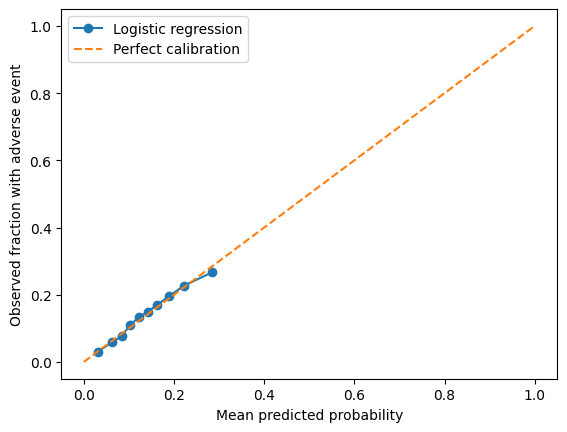

In [ ]:
frac_pos, mean_pred = calibration_curve(y_test, p_test, n_bins=10, strategy='quantile')

plt.plot(mean_pred, frac_pos, marker='o', label='Logistic regression')
plt.plot([0, 1], [0, 1], '--', label='Perfect calibration')
plt.xlabel('Mean predicted probability')
plt.ylabel('Observed fraction with adverse event')
plt.legend()
plt.show()

#shows that if model predictes 10% for group, 10% of group had adverse events (Good!)
# doesn't pick out correct people who has the adverse event (Bad!)

In [ ]:
coefs = pd.Series(logreg.coef_[0], index=X_train.columns)
odds_ratios = np.exp(coefs).sort_values(ascending=False)

print(odds_ratios.head(10))   # associated with higher risk
print(odds_ratios.tail(10))   # associated with lower risk

#weird that functional_scale_missing reduces odd of event by 96.15% (especially since the data is missing) 

ON_DIALYSIS_Y                      1.969273
INIT_AGE                           1.741981
ABO_B                              1.485913
functional_scale_unknown           1.284743
ABO_O                              1.220002
ETHCAT_6                           1.207699
A2A2B_ELIGIBILITY_NA_value         1.185371
ETHCAT_7                           1.137110
INIT_STAT_4099                     1.116539
functional_scale_not_applicable    1.096493
dtype: float64
REGION_6                             0.788672
REGION_3                             0.782374
REGION_11                            0.780977
ABO_AB                               0.780530
REGION_7                             0.675376
REGION_8                             0.654628
functional_scale_pediatric_lansky    0.653929
A2A2B_ELIGIBILITY_1.0                0.309100
ETHCAT_998                           0.282956
functional_scale_missing             0.038486
dtype: float64


In [ ]:
print(np.isfinite(X_train.to_numpy()).all())   # expect true, no inf or nan
print(logreg.n_iter_)                          # expect well under 1000, was 52 (model converged without needing extra space)

True
[52]


In [ ]:
for col in ['functional_scale_missing', 'ETHCAT_998',
            'A2A2B_ELIGIBILITY_1.0', 'functional_scale_not_applicable']:
    mask = X_train[col] == 1
    print(col, "| patients:", mask.sum(), "| event rate:", round(y_train[mask].mean(), 3))

#functional_scale_missing: Out of 3,174 patients, only about 10 had an adverse event. (3% of adverse event) 
#       No real health pattern shows a group that never dies or gets too sick. 
#       Guess: these patients are mostly recent listings who are still waiting and so are counted as “no event,”

#ETHCAT_998 and A2A2B_ELIGIBILITY_1.0: 4% and 6% of adverse event 
#       They’re also probably tied to when or how patients were listed.

#functional_scale_not_applicable: only 91 patients, so about 6 events. 
#       With a group that small, shouldn’t be interpreted. Harmless to include (bc such little data) but uninformative.

functional_scale_missing | patients: 3174 | event rate: 0.003
ETHCAT_998 | patients: 1378 | event rate: 0.041
A2A2B_ELIGIBILITY_1.0 | patients: 8681 | event rate: 0.056
functional_scale_not_applicable | patients: 91 | event rate: 0.066


In [ ]:
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)  

def evaluate(drop_cols, label):
    cols = [c for c in X_train.columns if c not in drop_cols]
    m = LogisticRegression(max_iter=1000, random_state=42)
    m.fit(X_train[cols], y_train)
    p = m.predict_proba(X_test[cols])[:, 1]
    return {"model": label,
            "ROC-AUC": roc_auc_score(y_test, p),
            "PR-AUC":  average_precision_score(y_test, p),
            "Brier":   brier_score_loss(y_test, p),
            "Lift@10%": top_decile_lift(y_test, p)}

rows = [
    evaluate([], "baseline (all features)"),
    evaluate(['functional_scale_missing'], "drop functional_scale_missing"),
    evaluate(['functional_scale_missing', 'A2A2B_ELIGIBILITY_1.0'], "drop both proxy suspects"),
]
pd.DataFrame(rows).round(4)

##
# without functional_scale_missing; scores don't dramatically change
# without functional_scale_missing and A2AB_ELIGIBILITY_1.0 the scores also don't change much 
# these features are not influencing the poor prediction rates

,model,ROC-AUC,PR-AUC,Brier,Lift@10%
0,baseline (all features),0.6709,0.2279,0.1165,1.8852
1,drop functional_scale_missing,0.6682,0.2267,0.1167,1.8795
2,drop both proxy suspects,0.6665,0.2256,0.1168,1.8709


In [ ]:
raw = pd.read_csv("../data/processed/cleaned_waitlist.csv")
train_raw = raw.loc[X_train.index]

print("OVERALL censored share:", round(train_raw['censored'].mean(), 3)) #percent of all training patients who were still waiting for a transplant when the data ended, their outcome unknown
print(train_raw['outcome'].value_counts(normalize=True).round(3), "\n")

for col in ['functional_scale_missing', 'A2A2B_ELIGIBILITY_1.0']:
    mask = X_train[col] == 1
    print("====", col)
    print("censored share:", round(train_raw.loc[mask, 'censored'].mean(), 3))
    print(train_raw.loc[mask, 'outcome'].value_counts(normalize=True).round(3))
    print(pd.to_datetime(train_raw.loc[mask, 'INIT_DATE']).dt.year.value_counts().sort_index(), "\n")

#  1,124 patients were listed in 2025 and 495 in 2026, compared with only 18 and 20 in 2015 and 2016. 
# 83% of these patients were still waiting when the data ended, so they were labeled 0 by default. 
# Died & removed too sick adds up to only about 0.3% (same rate seen earlier). 
# These patients mostly had no time to have an adverse event, so the 0.04 odds ratio is not a health effect.


OVERALL censored share: 0.209
outcome
transplanted              0.474
still_waiting             0.209
removed_administrative    0.091
transplanted_elsewhere    0.075
removed_too_sick          0.071
died                      0.069
unknown                   0.010
Name: proportion, dtype: float64 

==== functional_scale_missing
censored share: 0.834
outcome
still_waiting             0.834
removed_administrative    0.086
transplanted              0.073
transplanted_elsewhere    0.003
removed_too_sick          0.002
died                      0.001
unknown                   0.001
Name: proportion, dtype: float64
INIT_DATE
2015      18
2016      20
2017      19
2018      21
2019      21
2020      23
2021      23
2022      30
2023      34
2024      37
2025      35
2026    2893
Name: count, dtype: int64 

==== A2A2B_ELIGIBILITY_1.0
censored share: 0.202
outcome
transplanted              0.636
still_waiting             0.202
transplanted_elsewhere    0.065
removed_administrative    0.038
removed